In [1]:
import xarray as xr
import numpy as np
import os
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import matplotlib.patches as patches
import coare36vn_zrf_et as coare
import sklearn.metrics as metrics
import xskillscore
import scipy.stats as stats

import importlib
importlib.reload(coare);

In [43]:
#convert into numpy ndarray arrays
arr_1 = era5_lhf.values
arr_2 = airs_lhf.values
#Get coordinates from the original xarray
lat  = era5_lhf.coords['lat']
long = era5_lhf.coords['lon']

t_stat, p_values = stats.ttest_ind(arr_1, arr_2, equal_var = False, nan_policy = 'omit')
t_stat[p_values>0.05]=np.nan

#Write arrays into a x-array
t_stat_xr = xr.DataArray(t_stat, coords = [lat, long], dims = ['lat', 'lon'], name='t_stats')
p_val_xr = xr.DataArray(p_values, coords = [lat, long], dims = ['lat', 'lon'], name='p_value') 

/Users/anniefeng/.iron_man/lib/python3.13/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)


In [2]:
default = xr.open_mfdataset(
    "/Users/anniefeng/data/daily/2019_fixed_zi/*.nc", combine='nested', concat_dim="time"
)

In [3]:
# load era5 data
ds = xr.open_mfdataset(
    "/Users/anniefeng/data/daily/2019/*.nc", combine='nested', concat_dim="time"
)

In [4]:
seasons = ["DJF", "MAM", "JJA", "SON"]
proj=ccrs.PlateCarree()

In [4]:
airs_lhf_data = ds.airs_lhf_computed

for i in range(4):
    test_mean = airs_lhf_data.sel(time = airs_lhf_data["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        airs_seasonal = season_data

    else:
        airs_seasonal = xr.concat([airs_seasonal, season_data], dim = "season")

airs_seasonal

<xarray.DataArray 'airs_lhf_computed' (season: 4, lat: 400, lon: 1800)> Size: 12MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float32, chunksize=(1, 400, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

In [5]:
era5_lhf_data = ds.lhf_computed

for i in range(4):
    test_mean = era5_lhf_data.sel(time = era5_lhf_data["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        era5_seasonal = season_data

    else:
        era5_seasonal = xr.concat([era5_seasonal, season_data], dim = "season")

era5_seasonal

<xarray.DataArray 'lhf_computed' (season: 4, lat: 400, lon: 1800)> Size: 12MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float32, chunksize=(1, 145, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

# LHF

In [7]:
difference = ds.airs_lhf_computed - ds.lhf_computed

for i in range(4):
    test_mean = difference.sel(time = difference["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        diff_lhf = season_data

    else:
        diff_lhf = xr.concat([diff_lhf, season_data], dim = "season")

diff_lhf

<xarray.DataArray (season: 4, lat: 400, lon: 1800)> Size: 12MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float32, chunksize=(1, 145, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

In [11]:
lhf_rmse = xskillscore.rmse(ds.lhf.where(ds["wind_speed"] < 5).load(), ds.lhf_computed.where(ds["wind_speed"] < 5).load(), 
                            dim = 'time', skipna = True)

fig, ax = plt.subplots(figsize = (12,10), subplot_kw=dict(projection=ccrs.PlateCarree()))

# cmap = mpl.cm.viridis
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

ds.lhf.plot(transform = ccrs.PlateCarree(central_longitude=180), 
          ax = ax, #cmap = cmap, norm = norm,
          cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("RMSE in LHF (wind speed < 5)");

KeyboardInterrupt: 

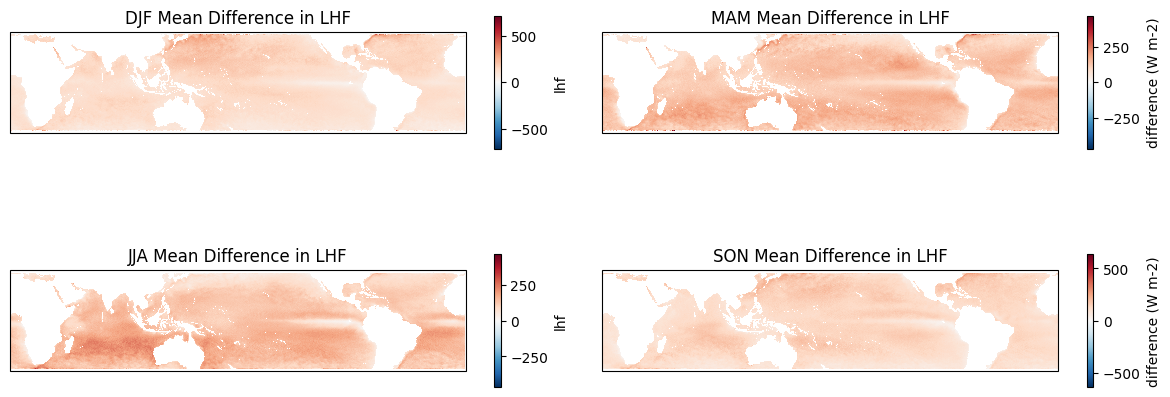

In [14]:
fig = plt.figure(figsize=(12, 6))
proj=ccrs.PlateCarree()

bounds = np.linspace(-20,20,9)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

for i in range(len(seasons)):
    
    if i%2 == 1:
        cbar_kwarg = {'shrink': 0.4, 'label': "difference (W m-2)"}

    else:
        cbar_kwarg = {'shrink': 0.4}
    
    ax = plt.subplot(2 , 2, i+1, projection = proj)
    to_plot = diff_lhf.sel(season = seasons[i])
    to_plot.plot(ax = ax, transform = ccrs.PlateCarree(central_longitude=180),
                 cbar_kwargs=cbar_kwarg)

    ax.set_title(seasons[i] + " Mean Difference in LHF")

plt.tight_layout()

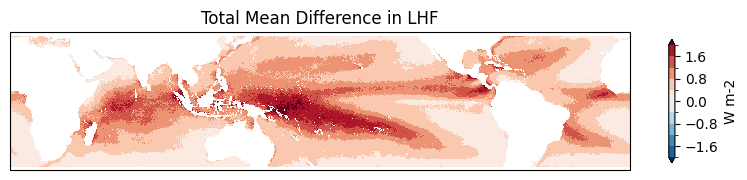

In [9]:
# total mean
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))

bounds = np.linspace(-2,2,11)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

difference = ds.airs_lhf_computed - ds.lhf_computed

(difference.mean(dim = "time", skipna = True)).plot(transform = ccrs.PlateCarree(central_longitude=180), 
                ax = ax, cmap = cmap, norm = norm,
                cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("Total Mean Difference in LHF");

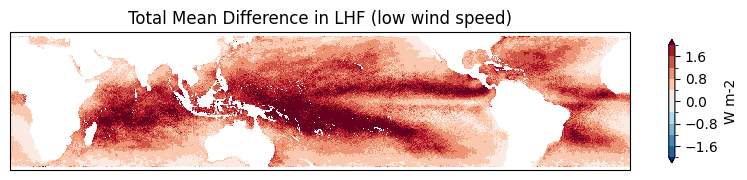

In [12]:
# total mean
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))

bounds = np.linspace(-3,3,11)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

difference = ds.airs_lhf_computed - ds.lhf_computed
diff_lhf = difference.where(ds["wind_speed"] < 5)

(diff_lhf.mean(dim = "time", skipna = True)).plot(transform = ccrs.PlateCarree(central_longitude=180), 
                ax = ax, cmap = cmap, norm = norm,
                cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("Total Mean Difference in LHF (low wind speed)");

# SHF

/Users/anniefeng/.iron_man/lib/python3.13/site-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: After omitting NaNs, one or more axis-slices of one or more sample arguments is too small; corresponding elements of returned arrays will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)
/Users/anniefeng/.iron_man/lib/python3.13/site-packages/scipy/stats/_stats_py.py:6195: RuntimeWarning: invalid value encountered in scalar divide
  svar = ((n1 - 1) * v1 + (n2 - 1) * v2) / df


KeyboardInterrupt: 

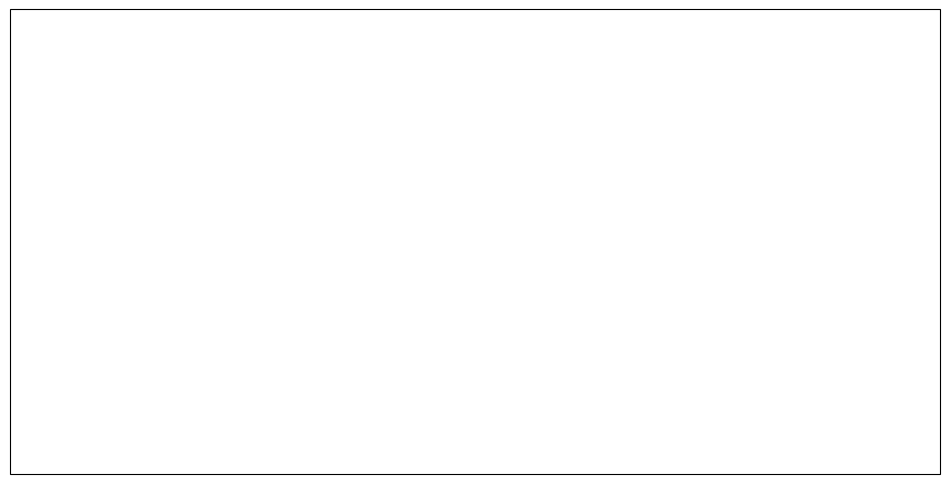

In [96]:
test = (ds.shf_computed - ds.airs_shf_computed).where(ds["wind_speed"] < 5)


fig, ax = plt.subplots(figsize = (12,10), subplot_kw=dict(projection=ccrs.PlateCarree()))

bounds = np.linspace(0,0.05,11)

cmap = mpl.cm.viridis
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

to_plot, _ = stats.ttest_ind(ds.shf_computed.where(ds["wind_speed"] < 5), ds.airs_shf_computed.where(ds["wind_speed"] < 5), 
                          nan_policy = 'omit')

# to_plot.plot(transform = ccrs.PlateCarree(central_longitude=180), 
#           ax = ax, cmap = cmap, norm = norm,
#           cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
# ax.set_title("test");

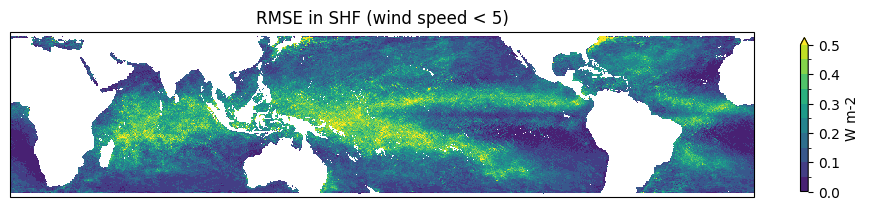

In [87]:
shf_rmse = xskillscore.rmse(ds.shf_computed.where(ds["wind_speed"] < 5).load(), ds.airs_shf_computed.where(ds["wind_speed"] < 5).load(), 
                            dim = 'time', skipna = True)

fig, ax = plt.subplots(figsize = (12,10), subplot_kw=dict(projection=ccrs.PlateCarree()))

bounds = np.linspace(0,0.5,11)

cmap = mpl.cm.viridis
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

shf_rmse.plot(transform = ccrs.PlateCarree(central_longitude=180), 
          ax = ax, cmap = cmap, norm = norm,
          cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("RMSE in SHF (wind speed < 5)");

In [10]:
difference = ds.shf_computed - ds.airs_shf_computed

for i in range(4):
    test_mean = difference.sel(time = difference["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        diff_shf = season_data

    else:
        diff_shf = xr.concat([diff_shf, season_data], dim = "season")

diff_shf

<xarray.DataArray (season: 4, lat: 400, lon: 1800)> Size: 12MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float32, chunksize=(1, 145, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

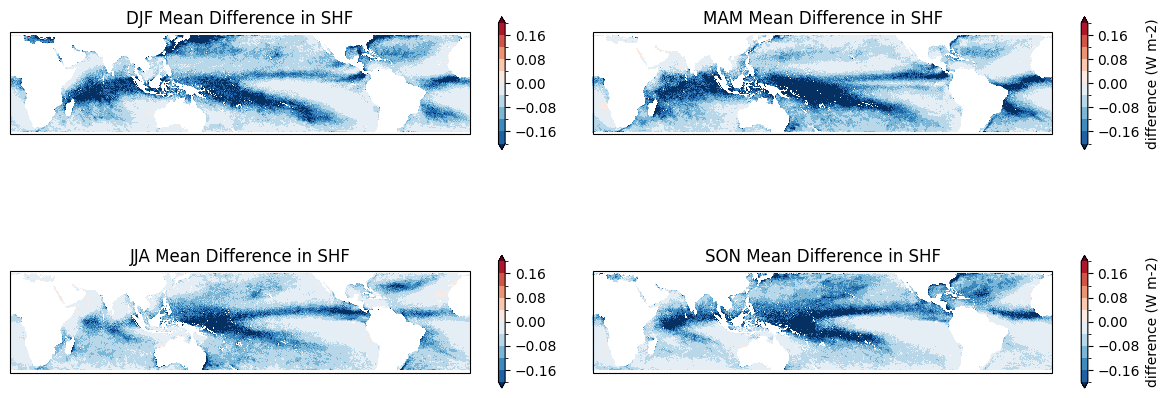

In [27]:
fig = plt.figure(figsize=(12, 6))
proj=ccrs.PlateCarree()

bounds = np.linspace(-0.2,0.2,11)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

for i in range(len(seasons)):
    
    if i%2 == 1:
        cbar_kwarg = {'shrink': 0.4, 'label': "difference (W m-2)"}

    else:
        cbar_kwarg = {'shrink': 0.4}
    
    ax = plt.subplot(2 , 2, i+1, projection = proj)
    to_plot = diff_shf.sel(season = seasons[i])
    to_plot.plot(ax = ax, transform = ccrs.PlateCarree(central_longitude=180), 
                 cmap = cmap, norm = norm, cbar_kwargs=cbar_kwarg)

    ax.set_title(seasons[i] + " Mean Difference in SHF")

plt.tight_layout()

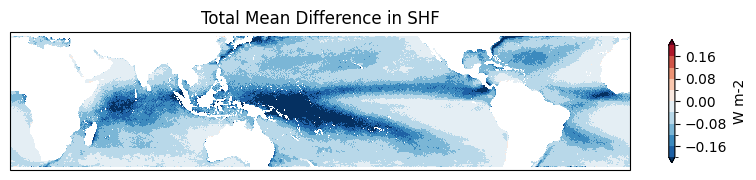

In [28]:
# total mean
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))

(diff_shf.mean(dim = "season", skipna = True)).plot(transform = ccrs.PlateCarree(central_longitude=180), 
                ax = ax, cmap = cmap, norm = norm,
                cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("Total Mean Difference in SHF");

# PBLH

In [8]:
difference = ds.airs_pblh - ds.pblh

for i in range(4):
    test_mean = difference.sel(time = difference["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        diff_pblh = season_data

    else:
        diff_pblh = xr.concat([diff_pblh, season_data], dim = "season")

diff_pblh

<xarray.DataArray (season: 4, lat: 400, lon: 1800)> Size: 23MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float64, chunksize=(1, 145, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

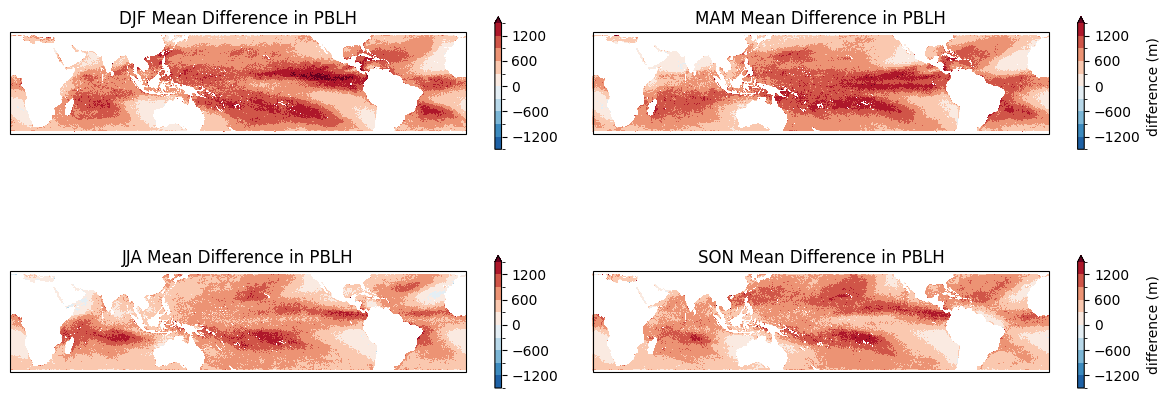

In [9]:
fig = plt.figure(figsize=(12, 6))
proj=ccrs.PlateCarree()

bounds = np.linspace(-1500,1500,11)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

for i in range(len(seasons)):
    
    if i%2 == 1:
        cbar_kwarg = {'shrink': 0.4, 'label':'difference (m)'}

    else:
        cbar_kwarg = {'shrink': 0.4}
    
    ax = plt.subplot(2 , 2, i+1, projection = proj)
    to_plot = (diff_pblh).sel(season = seasons[i])
    to_plot.plot(ax = ax, transform = ccrs.PlateCarree(central_longitude=180), 
                 cmap = cmap, norm = norm, cbar_kwargs=cbar_kwarg)

    ax.set_title(seasons[i] + " Mean Difference in PBLH")

plt.tight_layout()

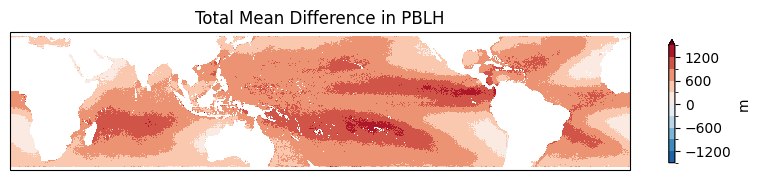

In [31]:
# total mean
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))

bounds = np.linspace(-1500,1500,11)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

(diff_pblh.mean(dim = "season", skipna = True)).plot(transform = ccrs.PlateCarree(central_longitude=180), 
                ax = ax, cmap = cmap, norm = norm,
                cbar_kwargs={'shrink': 0.2, 'label': "m"})
ax.set_title("Total Mean Difference in PBLH");

# Comparing

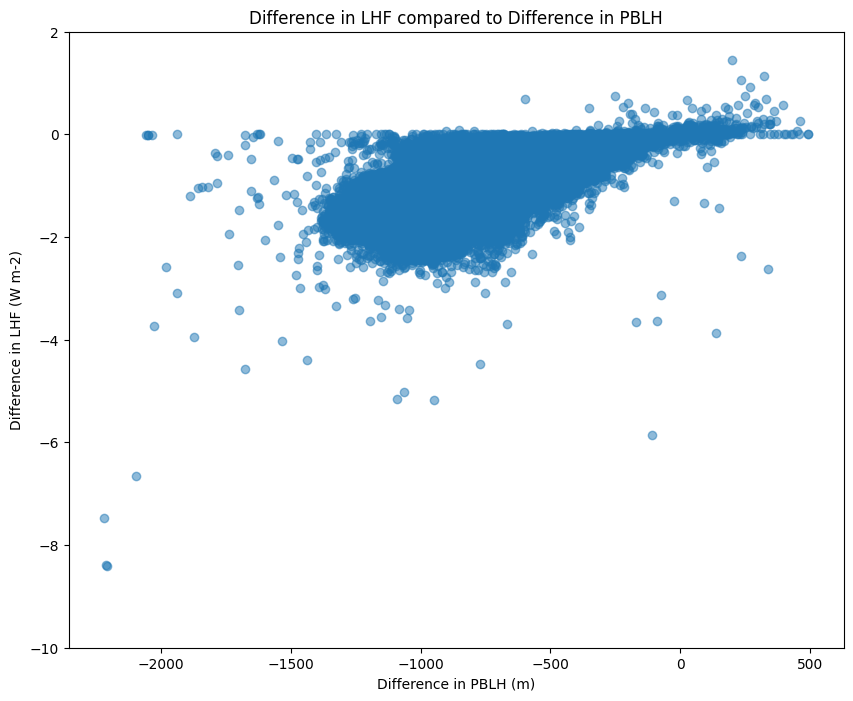

In [39]:
fig, ax = plt.subplots(figsize = (10,8))

x_values = diff_pblh.mean(dim = "season", skipna = True).values.reshape(400*1800)
y_values = diff_lhf.mean(dim = "season", skipna = True).values.reshape(400*1800)

ax.scatter(x_values, y_values, alpha = 0.5)
#ax.set_xlim(-2000,0)
ax.set_ylim(-10,2)
ax.set_xlabel("Difference in PBLH (m)")
ax.set_ylabel("Difference in LHF (W m-2)")

ax.set_title("Difference in LHF compared to Difference in PBLH");

In [52]:
def regional_mean(lats, lons, data_seasonal, lons_double):
    '''
    Selects a region based on lats and lons range provided and calculates, for each data set
    (airs, gps), the means of DJF, JJA, and total mean

    Returns 1 list of length 3 with the above means

    Parameters
    ---------------
    lats - latitude range
    lons - longitude range
    data_seasonal - xarray dataset with season coordinate
    data_total - xarray dataset with total mean over time
    '''
    data_total = data_seasonal.mean(dim = "season", skipna = True)
    
    temp = data_seasonal.sel(lat = lats, lon = lons[0])
    djf = float(temp.sel(season = "DJF").mean(skipna = True).values)
    jja = float(temp.sel(season = "JJA").mean(skipna = True).values)
    total = float(data_total.sel(lat = lats, lon = lons[0]).mean(skipna = True).values)
    
    temp_mean = np.array([djf, jja, total])

    if lons_double == True:
        # double coordinates
        temp_2 = data_seasonal.sel(lat = lats, lon = lons[1])
        djf_2 = float(temp.sel(season = "DJF").mean(skipna = True).values)
        jja_2 = float(temp.sel(season = "JJA").mean(skipna = True).values)
        total_2 = float(data_total.sel(lat = lats, lon = lons[1]).mean(skipna = True).values)

        temp_mean += np.array([djf_2, jja_2, total_2])

    return temp_mean

In [53]:
def regional_std(lats, lons, data_seasonal, lons_double):
    '''
    Selects a region based on lats and lons range provided and calculates, for each data set
    (airs, gps, era5, era5_itp), the standard deviations of DJF, JJA, and total mean

    Returns 1 list of length 3 with the above std

    Parameters
    ---------------
    lats - latitude range
    lons - longitude range
    data_seasonal - xarray dataset with season coordinate
    data_total - xarray dataset with total mean over time
    '''

    data_total = data_seasonal.mean(dim = "season", skipna = True)
    
    temp = data_seasonal.sel(lat = lats, lon = lons[0])
    djf = float(temp.sel(season = "DJF").std(skipna = True).values)
    jja = float(temp.sel(season = "JJA").std(skipna = True).values)
    total = float(data_total.sel(lat = lats, lon = lons[0]).std(skipna = True).values)
    
    temp_std = np.array([djf, jja, total])

    if lons_double == True:
        # double coordinates
        temp_2 = data_seasonal.sel(lat = lats, lon = lons[1])
        djf_2 = float(temp.sel(season = "DJF").std(skipna = True).values)
        jja_2 = float(temp.sel(season = "JJA").std(skipna = True).values)
        total_2 = float(data_total.sel(lat = lats, lon = lons[1]).std(skipna = True).values)

        temp_std += np.array([djf_2, jja_2, total_2])

    return temp_std

In [54]:
default_temp = default.lhf_computed

for i in range(4):
    test_mean = default_temp.sel(time = default_temp["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        default_data = season_data

    else:
        default_data = xr.concat([default_data, season_data], dim = "season")

default_data

<xarray.DataArray 'lhf_computed' (season: 4, lat: 400, lon: 1800)> Size: 12MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float32, chunksize=(1, 1, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9

In [55]:
era5 = ds.lhf_computed

for i in range(4):
    test_mean = era5.sel(time = era5["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        era5_data = season_data

    else:
        era5_data = xr.concat([era5_data, season_data], dim = "season")

era5_data

<xarray.DataArray 'lhf_computed' (season: 4, lat: 400, lon: 1800)> Size: 12MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float32, chunksize=(1, 145, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

In [56]:
airs = ds.airs_lhf_computed

for i in range(4):
    test_mean = airs.sel(time = airs["time.season"] == seasons[i]).mean(dim = "time", skipna = True)
    season_data = test_mean.expand_dims(season = [seasons[i]])

    if i == 0:
        airs_data = season_data

    else:
        airs_data = xr.concat([airs_data, season_data], dim = "season")

airs_data

<xarray.DataArray 'airs_lhf_computed' (season: 4, lat: 400, lon: 1800)> Size: 12MB
dask.array<concatenate, shape=(4, 400, 1800), dtype=float32, chunksize=(1, 400, 1800), chunktype=numpy.ndarray>
Coordinates:
  * season   (season) object 32B 'DJF' 'MAM' 'JJA' 'SON'
  * lat      (lat) float64 3kB -39.9 -39.7 -39.5 -39.3 ... 39.3 39.5 39.7 39.9
  * lon      (lon) float64 14kB 0.1 0.3 0.5 0.7 0.9 ... 359.3 359.5 359.7 359.9

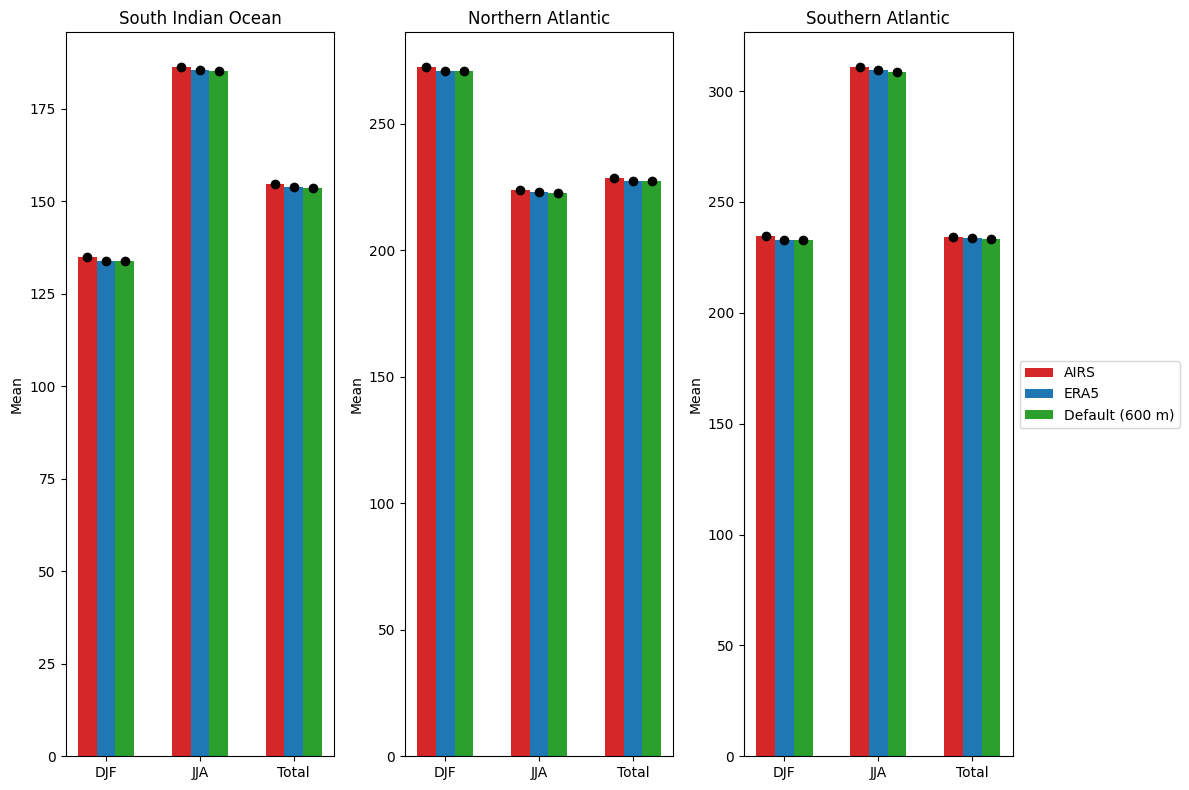

In [60]:
# plotting seasonal mean
fig = plt.figure(figsize=(12, 8))
x = np.arange(3)
width = 0.2

subregions = ["South Indian Ocean", "Northern Atlantic", "Southern Atlantic"]

# # airs first (goes backwards + -> -)
# lats_use = np.array(([slice(0,-30), slice(-30,0)],
#                     [slice(25,0), slice(0,25)],
#                     [slice(0,-25), slice(-25,0)]))

lats_use = [slice(-30,0), slice(0,25), slice(-25,0)]

# # airs first and third (goes from -180 to 180)
# # era5, gps, second and fourth
# lons_use = np.array(([slice(50,100), slice(50,100), 0, 0],
#                     [slice(-48, 15), slice(312,360), 0, slice(0,15)],
#                     [slice(-48, 15), slice(312,360), 0, slice(0,15)]))

lons_use = np.array(([slice(50,100), 0],
                    [slice(312,360), slice(0,15)],
                    [slice(312,360), slice(0,15)]))


for i in range(3):    
    lons_double = False

    if i == 1 or i == 2:
        lons_double = True

    airs_mean = regional_mean(lats_use[i], lons_use[i], airs_data, lons_double)
    era5_mean = regional_mean(lats_use[i], lons_use[i], era5_data, lons_double)
    default_mean = regional_mean(lats_use[i], lons_use[i], default_data, lons_double)
    # era5_itp_mean = regional_mean(lats_use[i][1], lons_use[i], era5_itp_seasonal, era5_itp_total, lons_double, airs = False)

    airs_std = 1.96*regional_std(lats_use[i], lons_use[i], airs_data, lons_double)/np.sqrt(400*1800)
    era5_std = 1.96*regional_std(lats_use[i], lons_use[i], era5_data, lons_double)/np.sqrt(400*1800)
    default_std = 1.96*regional_std(lats_use[i], lons_use[i], default_data, lons_double)/np.sqrt(400*1800)
    # era5_itp_std = regional_std(lats_use[i][1], lons_use[i], era5_itp_seasonal, era5_itp_total, lons_double, airs = False)
    
    ax = plt.subplot(1, 3, i+1)
    ax.bar(x-0.2, airs_mean, width, color='tab:red')
    ax.bar(x, era5_mean, width, color='tab:blue')
    ax.bar(x+0.2, default_mean, width, color='tab:green')
    #ax.bar(x+0.3, era5_itp_mean, width, color='tab:green')

    ax.errorbar(x-0.2, airs_mean, yerr=airs_std, fmt="o", color="black")
    ax.errorbar(x, era5_mean, yerr=era5_std, fmt="o", color="black")
    ax.errorbar(x+0.2, default_mean, yerr=default_std, fmt="o", color="black")
    #ax.errorbar(x+0.3, era5_itp_mean, yerr=era5_itp_std, fmt="o", color="black")
    
    ax.set_xticks(x, ['DJF', 'JJA', 'Total'])
    ax.set_ylabel("Mean")

    if i == 2:
        ax.legend(["AIRS", "ERA5", "Default (600 m)"],loc='center left', bbox_to_anchor=(1, 0.5))

    ax.set_title(subregions[i])

plt.tight_layout()

# Buoy Matchup

In [2]:
buoy = pd.read_csv("/Users/anniefeng/data/buoy_matchups_ERA_AIRS_2019.csv")

In [3]:
buoy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13400 entries, 0 to 13399
Data columns (total 39 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   day                   13400 non-null  object 
 1   day_center            13400 non-null  object 
 2   source_file           13400 non-null  object 
 3   buoy_loc              13400 non-null  object 
 4   n_hours               13400 non-null  int64  
 5   buoy_latp             13400 non-null  float64
 6   buoy_lonp             13400 non-null  float64
 7   buoy_lat              13400 non-null  float64
 8   buoy_lon              13400 non-null  float64
 9   buoy_ws10n            13400 non-null  float64
 10  buoy_ws10             13400 non-null  float64
 11  buoy_lhf              13400 non-null  float64
 12  buoy_shf              13400 non-null  float64
 13  buoy_time_first       13400 non-null  object 
 14  buoy_time_last        13400 non-null  object 
 15  match_status_era   

In [21]:
buoy["match_status_era"].unique()

array(['ok', 'no_finite_within_radius'], dtype=object)

In [4]:
test = buoy.set_index(['buoy_lat', 'buoy_lon','day'])
test = test.to_xarray().rename({'day':'time'})

In [5]:
test

<xarray.Dataset> Size: 42MB
Dimensions:               (buoy_lat: 19, buoy_lon: 21, time: 365)
Coordinates:
  * buoy_lat              (buoy_lat) float64 152B -12.0 -10.0 -8.0 ... 20.0 21.0
  * buoy_lon              (buoy_lon) float64 168B -180.0 -170.0 ... 156.0 165.0
  * time                  (time) object 3kB '2019-01-01' ... '2019-12-31'
Data variables: (12/36)
    day_center            (buoy_lat, buoy_lon, time) object 1MB nan nan ... nan
    source_file           (buoy_lat, buoy_lon, time) object 1MB nan nan ... nan
    buoy_loc              (buoy_lat, buoy_lon, time) object 1MB nan nan ... nan
    n_hours               (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    buoy_latp             (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    buoy_lonp             (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    ...                    ...
    grid_lat_airs         (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    dist_km_airs          (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    airs_lhf_computed     (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    airs_shf_computed     (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    airs_airs_pblh        (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan
    time_diff_hours_airs  (buoy_lat, buoy_lon, time) float64 1MB nan nan ... nan

## Difference

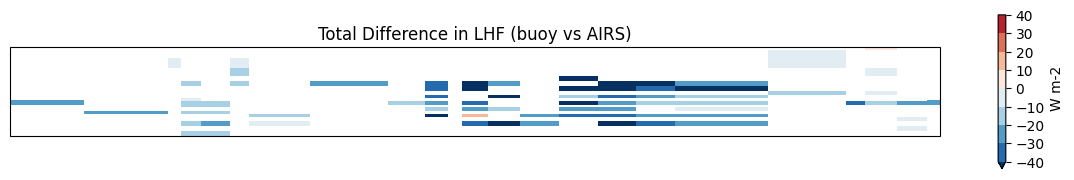

In [23]:
# difference between buoy and airs LHF
buoy_airs = (test.buoy_lhf - test.airs_lhf_computed).mean(dim = 'time', skipna = True)

fig, ax = plt.subplots(figsize = (15,10), subplot_kw=dict(projection=ccrs.PlateCarree()))

bounds = np.linspace(-40,40,9)

cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

buoy_airs.plot(transform = ccrs.PlateCarree(central_longitude=180), 
          ax = ax, cmap = cmap, norm = norm,
          cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("Total Difference in LHF (buoy vs AIRS)");

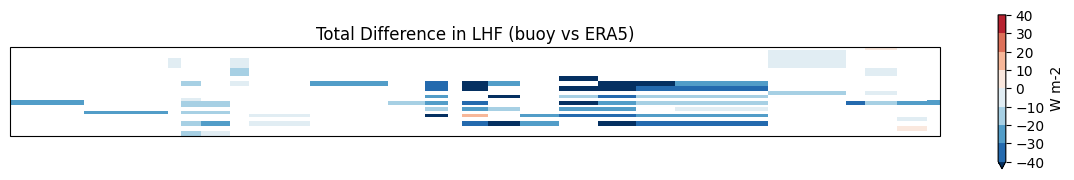

In [24]:
# difference between buoy and airs LHF
buoy_era = (test.buoy_lhf - test.era_lhf_computed).mean(dim = 'time', skipna = True)

fig, ax = plt.subplots(figsize = (15,10), subplot_kw=dict(projection=ccrs.PlateCarree()))

bounds = np.linspace(-40,40,9)

cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

buoy_era.plot(transform = ccrs.PlateCarree(central_longitude=180), 
          ax = ax, cmap = cmap, norm = norm,
          cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("Total Difference in LHF (buoy vs ERA5)");

## RMSE

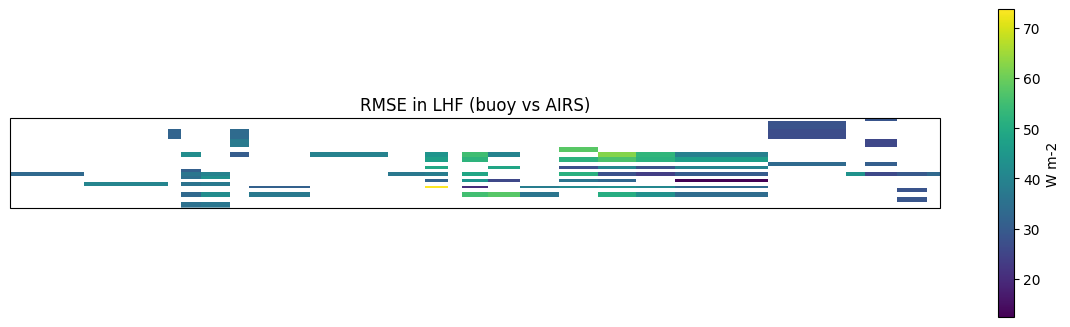

In [10]:
buoy_rmse = xskillscore.rmse(test.buoy_lhf, test.airs_lhf_computed, dim = 'time', skipna = True)

fig, ax = plt.subplots(figsize = (15,20), subplot_kw=dict(projection=ccrs.PlateCarree()))

# bounds = np.linspace(0,3,13)

# cmap = mpl.cm.viridis
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

buoy_rmse.plot(transform = ccrs.PlateCarree(central_longitude=180), 
          ax = ax, #cmap = cmap, norm = norm,
          cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("RMSE in LHF (buoy vs AIRS)");

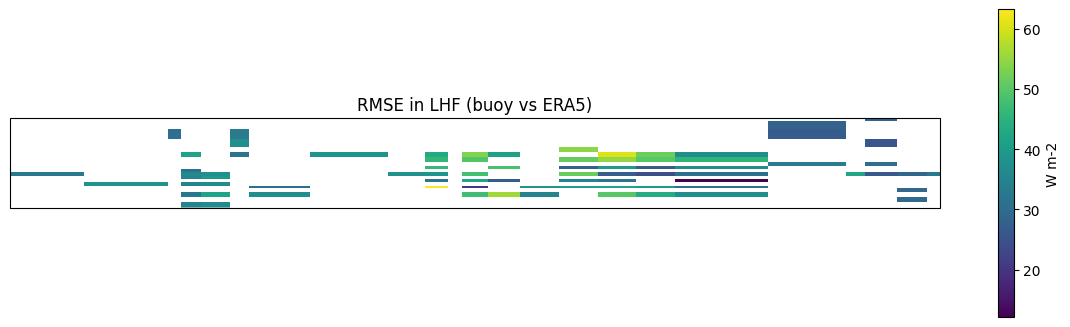

In [11]:
buoy_rmse_2 = xskillscore.rmse(test.buoy_lhf, test.era_lhf_computed, dim = 'time', skipna = True)

fig, ax = plt.subplots(figsize = (15,20), subplot_kw=dict(projection=ccrs.PlateCarree()))

# bounds = np.linspace(0,3,13)

# cmap = mpl.cm.viridis
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

buoy_rmse_2.plot(transform = ccrs.PlateCarree(central_longitude=180), 
          ax = ax, #cmap = cmap, norm = norm,
          cbar_kwargs={'shrink': 0.2, 'label': "W m-2"})
ax.set_title("RMSE in LHF (buoy vs ERA5)");

In [ ]:
for i in range(3):    
    lons_double = False

    if i == 1 or i == 2:
        lons_double = True

    airs_mean = regional_mean(lats_use[i], lons_use[i], airs_data, lons_double)
    era5_mean = regional_mean(lats_use[i], lons_use[i], era5_data, lons_double)
    default_mean = regional_mean(lats_use[i], lons_use[i], default_data, lons_double)
    # era5_itp_mean = regional_mean(lats_use[i][1], lons_use[i], era5_itp_seasonal, era5_itp_total, lons_double, airs = False)

    airs_std = 1.96*regional_std(lats_use[i], lons_use[i], airs_data, lons_double)/np.sqrt(400*1800)
    era5_std = 1.96*regional_std(lats_use[i], lons_use[i], era5_data, lons_double)/np.sqrt(400*1800)
    default_std = 1.96*regional_std(lats_use[i], lons_use[i], default_data, lons_double)/np.sqrt(400*1800)
    # era5_itp_std = regional_std(lats_use[i][1], lons_use[i], era5_itp_seasonal, era5_itp_total, lons_double, airs = False)
    
    ax = plt.subplot(1, 3, i+1)
    ax.bar(x-0.2, airs_mean, width, color='tab:red')
    ax.bar(x, era5_mean, width, color='tab:blue')
    ax.bar(x+0.2, default_mean, width, color='tab:green')
    #ax.bar(x+0.3, era5_itp_mean, width, color='tab:green')

    ax.errorbar(x-0.2, airs_mean, yerr=airs_std, fmt="o", color="black")
    ax.errorbar(x, era5_mean, yerr=era5_std, fmt="o", color="black")
    ax.errorbar(x+0.2, default_mean, yerr=default_std, fmt="o", color="black")
    #ax.errorbar(x+0.3, era5_itp_mean, yerr=era5_itp_std, fmt="o", color="black")
    
    ax.set_xticks(x, ['DJF', 'JJA', 'Total'])
    ax.set_ylabel("Mean")

    if i == 2:
        ax.legend(["AIRS", "ERA5", "Default (600 m)"],loc='center left', bbox_to_anchor=(1, 0.5))

    ax.set_title(subregions[i])

plt.tight_layout()

# testing

In [ ]:
rh = coare.RHcalc(test.ta.values.reshape(400*1800), test.pressure.values.reshape(400*1800), test.qa.values.reshape(400*1800), Tf)
rh.shape

In [ ]:
test.qa

In [ ]:
x = np.array([1, 2, 3])
result_times = np.repeat(test.lat.values, 1800) 
x_single = list(np.array([1, 2]))
np.array(list(test.lon.values)*400)

In [ ]:
test.ts

In [ ]:
u = test.wind_speed.values.reshape(400*1800)
zu = 10
t = test.ta.values.reshape(400*1800)
zt = 2

Ss = 35
Tf = - 0.0575 * Ss + 0.00171052 * Ss ** 1.5 - np.multiply(0.0002154996 * Ss,Ss)
rh = coare.RHcalc(test.ta.values.reshape(400*1800), test.pressure.values.reshape(400*1800), 
                  test.qa.values.reshape(400*1800), Tf)
zq = 2
P = test.pressure.values.reshape(400*1800)
ts = test.ts.values.reshape(400*1800)
sw_dn = 0
lw_dn = 0
lat = 15
lon = 100
jd = 0
zi = test.pblh.values.reshape(400*1800)
rain = np.full(400*1800,0)
Ss = np.full(400*1800,35)
cp = None
sigH = None
zrf_u, zrf_t, zrf_q = 10, 10, 10

In [ ]:
A=coare.coare36vn_zrf_et(u, zu , t, zt, rh, zq, P, ts, sw_dn, lw_dn, lat, lon,jd, zi,rain, Ss, cp, 
                         sigH, zrf_u, zrf_t, zrf_q)

In [ ]:
# calculated latent heat flux
calc_lhf = A[:,1]

In [ ]:
actual = test.lhf.values.reshape(400*1800)

In [ ]:
# hsb = shf, hlb = lhf
x = xr.Dataset(
    {
        "shf": (("lat", "lon"), A[:,0].reshape(400, 1800)),
        "lhf": (("lat", "lon"), A[:,1].reshape(400, 1800)),
        "Ch": (("lat", "lon"), A[:,2].reshape(400, 1800)),
        "Ce": (("lat", "lon"), A[:,3].reshape(400, 1800)),
        "gust": (("lat", "lon"), A[:,4].reshape(400, 1800)),
    },
    coords={"lat": test.lat.values, "lon": test.lon.values},
)

In [ ]:
fig, ax = plt.subplots(figsize = (10,8), subplot_kw=dict(projection=ccrs.PlateCarree()))
bounds = np.linspace(-600,600,13)

# mpl.cm.viridis
cmap = mpl.cm.RdBu_r
norm = mpl.colors.BoundaryNorm(bounds, cmap.N, extend='both')

x.lhf.plot(transform = ccrs.PlateCarree(), 
                ax = ax, cmap = cmap, norm = norm,
                cbar_kwargs={'shrink': 0.2})
ax.set_title("calc lhf");

In [ ]:
test.lhf.plot()

In [ ]:
test.wind_speed.values